# DENFIS method integration draft

LIN Jingzhao / HU Junyu. Not frozen; merge these cells with the data/evaluation sections. Runs offline from either repository root or writing/. No holdout evaluation.

In [1]:
from pathlib import Path
import os, sys
root = Path.cwd()
if not (root / 'config.py').exists():
    root = root.parent
assert (root / 'config.py').exists()
os.chdir(root)
sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print('Local data:', sorted(p.name for p in (root/'data/raw').glob('*.csv')))

Local data: ['D05_SI.csv', 'STI.csv']


# Method-line report draft

Author responsibility: LIN Jingzhao. Prepared 2026-11-10 for HU Junyu's notebook
integration. This is an English draft, not the frozen submission. The source
register is `docs/refs.md`; result tables and method-side figures must be
regenerated from saved experiment artifacts. No instructor approval is implied.

## Literature review

### Adaptive fuzzy models and evolving structure

A neuro-fuzzy model combines a fuzzy representation of local input regions with
parameters estimated from data. The fuzzy rules offer an explicit intermediate
representation: a prediction can be decomposed into rule activation and local
consequent output. This representation is useful only if the explanation names
its variables, scales, and assumptions. A large set of numeric rules is not
automatically interpretable, and an interpretable architecture does not guarantee
that its fitted rules describe an economically meaningful relationship.

Jang's ANFIS (1993) is an early adaptive-network formulation for fuzzy inference.
It provides a useful reference for connecting membership functions, rule
activations, and consequent estimation within a learning system. Its importance
here is conceptual rather than empirical: we do not run ANFIS as an additional
baseline. A distinction relevant to this project is whether model structure is
specified before training or can change as new input regions appear. Financial
features can change their distribution over time, motivating an investigation
of evolving structure without assuming that evolution will improve prediction.

Song and Kasabov's ECM manuscript (2001) describes an incremental geometric
partition of an input stream. Its state consists of centres and radii rather
than a stored copy of all historical observations. A radius threshold controls
when the partition expands and when a new region is required. This makes ECM a
natural antecedent generator for local fuzzy predictors. The distance
normalisation is important: thresholds stated in a dimension-normalised metric
cannot be silently substituted into ordinary Euclidean distance. Our code and
method notes specify the metric so that the grid is reproducible.

Kasabov and Song's DENFIS (2002) couples evolving fuzzy structure with local
inference for time-series prediction. The original work covers online and
offline formulations and dynamically selected activated rules. We adopt the
broader ECM/TSK/local-estimation approach, while following this project's fixed
Gaussian and weighted-RLS protocol. We therefore describe the implemented model
as a DENFIS-inspired variant and list its deviations. The established DENFIS
algorithm is not our invention; the contribution is an independently written,
bounded implementation and a controlled comparison of its frozen and adapting
forms on this dataset.

### Related evolving systems and modern directions

Angelov and Filev (2004) study online identification of evolving Takagi–Sugeno
models. Their work places DENFIS within a wider family of systems that adapt
structure and local parameters from streams. Rong and colleagues' SAFIS (2006)
uses rule influence in sequential structural adaptation. The year is 2006,
correcting the 2008 date in the original workplan. Pratama and colleagues' PANFIS
(2014) provides another incremental fuzzy-learning architecture. These methods
motivate questions about model size, structural adaptation, and local learning;
we do not report comparative scores for implementations that we did not run.

Recent deep neuro-fuzzy research expands the representational setting beyond
small tabular systems. Yeganejou and colleagues' DCNFIS preprint (2023, revised
2024) investigates convolutional neuro-fuzzy modelling and explanations for
visual data. Its application domain differs substantially from daily financial
returns. It supports a future research direction, not a claim that its reported
accuracy transfers to DBS or that our model matches contemporary state of the
art. Alateeq and Pedrycz's 2024 logic-oriented fuzzy-neural survey provides additional
review context, especially the relation between rule representation and
interpretation. Its discussion is distinct from our empirical return task.

### Baselines and scope of comparison

Chen and Guestrin's XGBoost (2016) supplies a regularised nonlinear tree baseline.
Hochreiter and Schmidhuber's LSTM (1997) supplies the recurrent modelling basis
for the temporal baseline. The repository's LSTM receives twenty-day sequences
of the thirteen features; DENFIS and XGBoost receive the current feature vector.
This difference expresses their inductive biases and must be disclosed. We do
not describe the three inputs as identical simply because their feature names
match. Hyperparameter budgets also differ and are listed in the shared protocol.

| Family | Structural idea | Role in this study |
|---|---|---|
| ANFIS | Adaptive-network fuzzy inference | Historical and architectural context |
| DENFIS / ECM | Evolving input regions and local inference | Basis of implemented method |
| eTS / SAFIS / PANFIS | Related sequential fuzzy adaptation | Literature context only |
| Deep neuro-fuzzy models | Learned representations with fuzzy components | Future direction only |
| XGBoost | Regularised boosted trees | Empirical baseline |
| LSTM | Recurrent sequence representation | Empirical baseline |

The evaluation question is deliberately narrow: under the same cached market
data, causal preprocessing, and chronological test windows, does this variant
produce useful return forecasts and a defensible long/flat strategy? Statistical
forecast comparison follows Diebold and Mariano (1995), while dependent-return
uncertainty is estimated with the stationary bootstrap of Politis and Romano
(1994). These tools quantify uncertainty; neither converts an exploratory
experiment into proof of future trading profitability.

## Method

### Prediction task and preprocessing boundary

For each feature row, the target is the next available trading day's logarithmic
return. The model sees only the thirteen-dimensional numerical feature vector
and target pairs supplied by the evaluation runner. It does not read dates,
prices, cached files, or network resources. The runner fits winsorisation bounds
and z-score statistics within the appropriate training window. The selection
stage and final refit have distinct training windows and therefore distinct
preprocessing fits. Feature order is fixed by `config.FEATURES`.

There are nine expanding test folds covering 2017–2025. For test year Y,
selection training ends in Y−2, validation occupies Y−1, and the final training
window includes data through Y−1 after parameter selection. Fold membership is
assigned by target realisation date. This prevents a training row whose target
belongs to a later period from crossing the split boundary. The separate 2026
holdout is not an additional validation window. Baseline holdout artifacts
already existed at handoff; our DENFIS experiments do not use that period before
the scheduled final freeze.

### ECM antecedent construction

Let x belong to R^d and let rule i have centre c_i and radius r_i. Define
D_i = ||x−c_i||_2 / sqrt(d). The first training input creates a centre with zero
radius. For a new input covered by an existing ball, retain its geometry and
increase support. Otherwise choose the rule minimising S_i = D_i+r_i. When
S_i > 2Dthr, create a new rule unless the configured rule limit is already
reached. If the limit prevents creation, retain the existing centres and assign
support to the closest rule. This is an explicit memory constraint rather than
an unbounded ECM guarantee.

For an admissible expansion, set r_i' = S_i/2 and move the centre toward the
input by c_i' = c_i + ((D_i−r_i')/D_i)(x−c_i). The implementation guards the zero
distance denominator. The radius threshold is selected from the protocol's five
values in the standardised, normalised-distance space. It is not tuned on test
returns. Smaller thresholds can require more local regions, but the rule cap
and merging mean that the final relationship need not be strictly monotone on
every real dataset.

The optional merge extension compares normalised centre distances with
merge_factor times Dthr. It retains the higher-support centre and its consequent,
adds the removed support count, and enlarges the surviving radius to enclose the
removed ball. In online training, the surviving consequent and covariance are
retained rather than averaged. New rules start from zero coefficients and the
same covariance initialisation as initial training. Merging may produce a
radius larger than Dthr, so bounded-radius properties of unmodified ECM must
not be claimed for the merged variant.

### Gaussian rule activation and TSK inference

For each rule set sigma_i = max(r_i, 0.1Dthr, 10^−6). The implementation computes
log activation l_i = −mean_j((x_j−c_ij)^2)/(2sigma_i^2), then normalises activations
with a softmax. In a product-of-coordinate-Gaussians interpretation, each
coordinate has width sqrt(d) times sigma_i. This dimension factor matters for
reproducing the actual rule firing. Subtracting the largest log activation
before exponentiation prevents all activations from underflowing together for
points far from every centre.

Each first-order TSK consequent is f_i(x) = theta_i^T phi with phi=[1,x]. The
ensemble prediction is the activation-weighted sum of these local outputs.
All rules contribute numerically; there is no original-paper top-m selection.
Predictions are clipped at a fixed absolute log-return bound of 0.2 as a numerical
safeguard. The threshold is not selected using observed test performance.
For synthetic regression tests with larger target scales, clipping can be
explicitly disabled. The distinction is documented so that a successful
synthetic test is not confused with the exact financial-output configuration.

### Weighted recursive least squares

Each rule maintains a coefficient vector of length d+1 and a covariance matrix
of size (d+1) by (d+1). Initialise coefficients to zero and covariance to 100I.
For normalised activation h_i and v_i=P_i phi, the update is:

$$K_i = \frac{h_i v_i}{\lambda+h_i\phi^T v_i},$$
$$\theta_i \leftarrow \theta_i + K_i(y-\theta_i^T\phi),$$
$$P_i \leftarrow (P_i-K_i v_i^T)/\lambda.$$

This is local weighted regression: the residual is relative to each rule's own
output, not the ensemble residual. Rules whose activation is below 10^−6 are
not updated or discounted on that sample. This avoids covariance inflation
for almost inactive regions and is a documented approximation. Covariances are
symmetrised after updating. Nonfinite state, a nonpositive diagonal, or a trace
above 10^8 resets the affected covariance and coefficients; counters expose
such resets rather than hiding them.

The numerical contract includes a one-rule check with lambda=1: sequential
updates must agree with the regularised least-squares solution implied by the
100I prior. This test checks the mathematics independently of the implementation
structure. Synthetic nonlinear generalisation, exact one-dimensional ECM
geometry, and state invariance under prediction provide additional evidence.
Passing them establishes important implementation properties, but does not
prove the implementation is an exact reproduction of the original publication.

### Batch fitting, online evaluation, and selection

Fitting has two chronological passes. The first learns antecedents from training
inputs and performs merging. The second replays the training input/target pairs
to estimate consequents with antecedents held fixed. Using future rows within
that training window to define the partition is permissible for a batch fit;
it must not be described as a single-pass joint online learner. Both passes
remain strictly inside the training boundary established by the shared runner.

The frozen model does not update during test evaluation. The online extension
first predicts a row, records its forecast, and only then calls partial_fit with
the realised target. That call may evolve antecedents and update consequents.
The current forecast therefore cannot depend on its own target. A dedicated
runner test records the calls and checks alternating predict/update events
against the expected target sequence. Online performance is reported in a
separate extension table because it uses information acquired during the test
period that the frozen model does not incorporate into parameters.

Twenty combinations of Dthr and lambda are evaluated on the validation year.
The runner chooses the smallest validation RMSE; exactly tied scores prefer
fewer rules and then a larger Dthr. After selecting hyperparameters and the
validation-based trading threshold, it refits on the final training window.
Search records, selected parameters, runtime, rule counts, cap hits, merges,
and covariance resets are persisted. The default all-fold selection excludes
the holdout; a regression test protects that boundary.

### Resource use and reproducibility

For N training samples, K rules and d features, local RLS has approximate cost
O(NKd^2) and covariance storage O(Kd^2). Prediction costs O(NKd). Pairwise merge
scans add O(K^2d) work per scan. K is capped at 200. The deterministic training
order is never shuffled; the seed interface is retained for consistency even
though the current algorithm draws no random numbers. Repeated fit calls reset
all learned state, and predict does not modify coefficients or diagnostics.

The shared runner saves predictions and metrics, rebuilds the summary, and
records source/data hashes and dependency versions. The numerical experiments
use Python 3.11 with the pinned numerical dependencies. Historical baseline
artifacts are retained rather than silently regenerated in a different
environment; their original manifest is preserved separately. Core implementation,
contracts, experiment runners, analysis scripts and report text are versioned
together so a reader can trace a claim back to an artifact.

## Analysis plan and interpretation boundaries

The main comparison contains frozen DENFIS, XGBoost and LSTM. The online
extension is a separate comparison with frozen DENFIS. Forecast metrics include
RMSE, MAE, R-squared, correlation and directional accuracy. Trading metrics
include Sharpe, annualised return, maximum drawdown, turnover and exposure after
the common one-way transaction cost. A strategy that stays flat much of the
time may reduce drawdown simply by taking less risk. That observation alone is
not evidence of better forecast skill or superior risk-adjusted performance.

The three representative folds are r1f1, r2f2 and r3f3. RLS ablation replaces the
first-order local consequent with a weighted running constant. It changes both
adaptation and functional complexity, so it is not a perfectly isolated test
of one update equation. The no-merge ablation uses the same frozen-selected
Dthr/lambda values and turns merging off. These variants inherit parameters
rather than receiving additional test-informed optimisation. Their prediction
and metric files are saved outside the main nine-fold result directories.

Sensitivity plots use the saved validation grid. For each Dthr, the curve shows
the minimum validation RMSE across lambda, and vice versa. This is a profile
minimum rather than an isolated test-set causal effect of one parameter. It
helps describe how validation-based selection behaves without using test
scores to reopen the search space. A rule-cap hit indicates that the bounded
approximation mattered; a zero merge count indicates that the merge mechanism
was inactive for that fit, not that merging has proven beneficial.

Interpretability figures show rule-count evolution, coordinate membership sets,
and contributions on a high-volatility test day. The day is chosen after the
fact by realised absolute return, solely to illustrate a difficult case. Its
identity is not supplied to training or used to select parameters. The top
rules are ranked by their average activation in the descriptive test analysis.
Marginal Gaussian sets are not the complete multidimensional firing surface,
and local coefficients describe fitted associations in standardised coordinates,
not causal economic effects.

Transfer analysis uses three chronological folds and three protocols: DBS-only
scratch training, STI-only zero-shot prediction, and STI pretraining followed by
DBS training-window adaptation. Both market frames are aligned by label date.
Each market fits its own scaler on the source or target training window used
at that stage. No source labels extend past the corresponding target cutoff. Strict zero-shot
parameter and trading-threshold selection also uses STI validation labels only;
it never uses DBS validation labels. Scratch and fine-tune use DBS validation.
Consequently, the rules are transferred between separately standardised spaces,
which assumes that corresponding feature coordinates describe sufficiently
related states. STI volume is often zero, weakening the interpretation of its
volume-derived feature. All transfer scores remain a limited extension rather
than being pooled into a nine-fold headline result.

## Future work

The first priority for future work is stronger evaluation of stability. A single
asset and nine dependent chronological windows offer limited evidence about
robustness across markets or regimes. Additional assets and explicitly separated
research and final-evaluation periods would allow a more credible assessment
of whether useful local rules persist. Any repeated reuse of a holdout should
be disclosed rather than relabelled as a new independent test. Confidence
intervals and paired loss comparisons should accompany point estimates.

Second, structural adaptation could be made more selective. The current merge
rule uses centre distance and support, and the rule cap can prevent a new region
from being represented. A drift-aware approach could distinguish persistent
new patterns from temporary outliers, or retire rarely activated rules using
only information already realised. Such mechanisms require explicit tests of
when a forecast becomes dependent on each new label. They should be compared
with the simpler fixed-structure and consequent-only alternatives before being
credited with better adaptation.

Third, uncertainty and numerical diagnostics could guide modelling choices.
The current covariance reset and forecast clipping are engineering safeguards,
not a calibrated predictive distribution. Reporting clipping frequency and
confidence calibration would help distinguish a stable estimator from a model
whose extreme outputs are merely suppressed. More principled regularisation
and conditioning checks may improve reliability without adding unnecessary
structural complexity. Adaptive forgetting remains a future extension rather
than a completed contribution in this study.

Finally, representation learning and richer information are possible directions,
but they increase the burden of causal data alignment. Deep fuzzy representations
would require more data and a fair compute budget. News sentiment would require
archived timestamps, documented availability delays and reproducible historical
coverage. The attempted GDELT retrieval was unavailable in the original environment
and contributes no main-result evidence. Transfer across related assets is a
more modest first extension, and even there a negative result can be informative:
shared macroeconomic exposure does not imply that the same standardised local
return relationship transfers unchanged.

## Preliminary nine-fold evidence (to be locked at the scheduled freeze)

The saved frozen run covers 2,258 out-of-sample predictions. Its pooled RMSE is
0.012066, MAE is 0.008564, R-squared is −0.0194, and directional accuracy is
0.5009. These values provide no basis for claiming strong next-day forecasting
skill. In particular, pooled RMSE is not lower than the historical XGBoost or
LSTM scores, and R-squared remains below zero. The model can represent nonlinear
synthetic data while still failing to extract a reliable forecasting advantage
from this financial task; these are different empirical questions.

Frozen DENFIS has a strategy Sharpe of 0.6541 and annualised return of 0.0701,
with maximum drawdown 0.2026 and exposure 0.3437. Its Sharpe point estimate is
larger than the historical XGBoost value of 0.2376 and LSTM value of 0.4066,
but smaller than buy-and-hold's 1.1125. Reduced exposure and drawdown therefore
need to be presented alongside the return sacrificed relative to remaining
invested. A point-estimate strategy ranking is not an independent demonstration
of superior forecast accuracy, and it should not be used to reopen the search
space after seeing the test years.

The stationary-bootstrap 95% interval for frozen Sharpe is approximately
[−0.041, 1.309]. It includes zero. The corresponding squared-error DM comparison
with XGBoost gives a positive statistic of 1.2306 and p=0.2185. A positive
statistic means frozen DENFIS has larger average squared loss in the aligned
sample, but the test does not reject equal mean loss at the conventional 5%
level. Failure to reject is not proof of equality or equivalence. The comparison
is exploratory, the reference baseline is chosen by pooled RMSE, and multiple
comparisons are not adjusted. These qualifications belong with the reported
numbers rather than being omitted from the conclusion.

The online extension does not improve this pooled comparison. Its RMSE is
0.012185, directional accuracy 0.5018, and strategy Sharpe 0.2595. Online Sharpe's
bootstrap interval is approximately [−0.413, 0.889]. Against frozen DENFIS, the
DM statistic is 1.0932 with p=0.2743. Thus continuous adaptation supplies no
statistically established improvement in this experiment. Possible explanations
include noisy daily labels and transient local updates, but the present study
does not isolate those mechanisms. The conservative statement is simply that
the implemented adaptation failed to improve the observed pooled scores.

Frozen fitting took approximately 225 seconds across the nine folds in the
recorded environment. Final rule counts range from 11 to 200, with three folds
reaching the configured cap and no final-fit covariance resets. One fold records
a merge, while most record none. These diagnostics explain why a no-merge ablation
may coincide with the full model in some folds: an available mechanism need not
actually be exercised in a particular fitted run. They also show that bounded
memory is a substantive modelling approximation for some years, not merely a
hypothetical safeguard. Runtime measurements are environment-specific and do
not guarantee a particular speed on another machine.

The baseline comparisons, frozen/online result tables, and statistical report
are generated from saved predictions. They remain preliminary until the planned
joint review and freeze. Instructor consultation, final holdout evaluation,
combined-notebook integration and the actual timed rehearsal have not yet taken
place. Keeping those events distinct from completed code execution makes the
handoff auditable and leaves the final presentation grounded in work that has
actually been done.

The ablation diagnostics also caution against crediting complexity automatically.
On r1f1 and r2f2, the weighted-constant variant has lower RMSE than the full local
linear model; on r3f3 its RMSE is slightly higher. Its strategy Sharpe is larger
on those three folds, but these selected examples do not establish a nine-fold
improvement. We also add r2f1 as a diagnostic fourth fold because it actually
exercises merging. Disabling merging there increases the final count from 66
to 67 and changes RMSE only slightly, from approximately 0.018200 to 0.018206.
The planned three representative folds have no final-fit merges, so identical
no-merge scores on them are expected. This additional fold is explanatory,
not a new main-model selection criterion. The complete variant table is saved
in `results/analysis/ablations.csv`.


## Complete core implementation

The source below is embedded for review, not hidden behind an import.

In [2]:
"""Bounded ECM / Gaussian TSK / local weighted-RLS research implementation.

See docs/denfis_notes.md for formulas and differences from original DENFIS.
Inputs must already be standardised; no dates, prices or files are accessed.
"""

from __future__ import annotations

import numpy as np

from config import DENFIS_MAX_RULES, DENFIS_MERGE_FACTOR, GLOBAL_SEED


class DENFIS:
    """First-order TSK rules learned with ECM and chronological weighted RLS.

    ``fit`` first learns antecedents from training X, then replays training
    pairs once to estimate consequents. ``partial_fit`` never resets state.
    ``evolve_rules`` controls antecedent adaptation during partial updates,
    not whether consequents may adapt. Predictions are pure reads.
    """

    name = "denfis"

    def __init__(
        self, dthr: float = 0.5, lam: float = 0.99,
        max_rules: int = DENFIS_MAX_RULES,
        merge_factor: float = DENFIS_MERGE_FACTOR,
        seed: int = GLOBAL_SEED, evolve_rules: bool = False,
        *, prediction_clip: float | None = 0.2, rls: bool = True,
    ):
        if not np.isfinite(dthr) or dthr <= 0:
            raise ValueError("dthr must be positive and finite")
        if not np.isfinite(lam) or not 0 < lam <= 1:
            raise ValueError("lam must be in (0, 1]")
        if int(max_rules) != max_rules or max_rules < 1:
            raise ValueError("max_rules must be a positive integer")
        if not np.isfinite(merge_factor) or not 0 <= merge_factor <= 1:
            raise ValueError("merge_factor must be in [0, 1]")
        if prediction_clip is not None and (
            not np.isfinite(prediction_clip) or prediction_clip <= 0
        ):
            raise ValueError("prediction_clip must be positive or None")
        self.dthr, self.lam = float(dthr), float(lam)
        self.max_rules, self.merge_factor = int(max_rules), float(merge_factor)
        self.seed, self.evolve_rules = int(seed), bool(evolve_rules)
        self.prediction_clip, self.rls = prediction_clip, bool(rls)

    @property
    def n_rules_(self) -> int:
        return len(self.centers_) if hasattr(self, "centers_") else 0

    def get_params(self) -> dict:
        return {key: getattr(self, key) for key in (
            "dthr", "lam", "max_rules", "merge_factor", "seed",
            "evolve_rules", "prediction_clip", "rls",
        )}

    def _inputs(self, X: np.ndarray, *, training: bool = False) -> np.ndarray:
        X = np.asarray(X, dtype=np.float64)
        if X.ndim != 2 or X.shape[1] == 0 or not np.isfinite(X).all():
            raise ValueError("X must be a finite (n, d) matrix with d > 0")
        if training and len(X) == 0:
            raise ValueError("empty training set")
        if not training:
            if not self.n_rules_:
                raise RuntimeError("fit must be called before prediction/update")
            if X.shape[1] != self.n_features_in_:
                raise ValueError("feature dimension mismatch")
        return X

    def _new_rule(self, x: np.ndarray) -> None:
        self.centers_ = np.vstack((self.centers_, x))
        self.radii_ = np.append(self.radii_, 0.0)
        self.support_ = np.append(self.support_, 1)
        p = self.n_features_in_ + 1
        self.coef_ = np.vstack((self.coef_, np.zeros(p)))
        self.cov_ = np.concatenate((self.cov_, (100.0 * np.eye(p))[None]))
        self.mass_ = np.append(self.mass_, 0.0)
        self.target_sum_ = np.append(self.target_sum_, 0.0)

    def _ecm_update(self, x: np.ndarray) -> int | None:
        if not self.n_rules_:
            self._new_rule(x)
            return 0
        changed = None
        distances = np.sqrt(np.mean((self.centers_ - x) ** 2, axis=1))
        inside = np.flatnonzero(distances <= self.radii_ + 1e-12)
        if len(inside):
            index = int(inside[np.argmin(distances[inside])])
        else:
            extended = distances + self.radii_
            index = int(np.argmin(extended))
            if extended[index] > 2 * self.dthr:
                if self.n_rules_ < self.max_rules:
                    self._new_rule(x)
                    return self.n_rules_ - 1
                # Bounded-memory extension: preserve antecedents at the cap.
                index = int(np.argmin(distances))
                self.cap_hits_ += 1
            else:
                radius = extended[index] / 2
                shift = (distances[index] - radius) / max(distances[index], 1e-12)
                self.centers_[index] += shift * (x - self.centers_[index])
                self.radii_[index] = radius
                changed = index
        self.support_[index] += 1
        return changed

    def _merge_rules(self, affected: int | None = None) -> None:
        if self.merge_factor == 0:
            return
        if affected is not None:
            # The previous state has no eligible pair. Only a newly created
            # or moved centre can introduce one; avoid an O(K^2 d) scan when
            # its O(K d) distance check already excludes a merge.
            distance = np.sqrt(np.mean((self.centers_ - self.centers_[affected]) ** 2, axis=1))
            distance[affected] = np.inf
            if np.min(distance) >= self.merge_factor * self.dthr:
                return
        while self.n_rules_ > 1:
            distance = np.sqrt(np.mean(
                (self.centers_[:, None] - self.centers_[None, :]) ** 2, axis=2
            ))
            np.fill_diagonal(distance, np.inf)
            i, j = np.unravel_index(np.argmin(distance), distance.shape)
            if distance[i, j] >= self.merge_factor * self.dthr:
                break
            if self.support_[j] > self.support_[i]:
                i, j = j, i
            # Keep the better-supported antecedent and its local fit. Enlarge
            # radius to enclose the removed ball; merge is a project extension.
            self.radii_[i] = max(self.radii_[i], distance[i, j] + self.radii_[j])
            self.support_[i] += self.support_[j]
            for attr in ("centers_", "radii_", "support_", "coef_", "cov_", "mass_", "target_sum_"):
                setattr(self, attr, np.delete(getattr(self, attr), j, axis=0))
            self.merges_ += 1

    def firing_strengths(self, X: np.ndarray) -> np.ndarray:
        """Return normalised Gaussian activations without modifying state."""
        X = self._inputs(X)
        width = np.maximum(self.radii_, max(0.1 * self.dthr, 1e-6))
        log_weight = -0.5 * np.mean(
            (X[:, None, :] - self.centers_[None, :, :]) ** 2, axis=2
        ) / width[None, :] ** 2
        log_weight -= np.max(log_weight, axis=1, keepdims=True)
        weights = np.exp(log_weight)
        return weights / weights.sum(axis=1, keepdims=True)

    def _update_consequents(self, x: np.ndarray, y: float) -> None:
        h = self.firing_strengths(x[None])[0]
        phi = np.r_[1.0, x]
        if not self.rls:
            self.mass_ += h
            self.target_sum_ += h * y
            self.coef_[:, 0] = self.target_sum_ / np.maximum(self.mass_, 1e-12)
            return
        # Tiny activations do not discount unused rules or inflate covariance.
        active = h >= 1e-6
        P = self.cov_[active]
        v = np.einsum("kij,j->ki", P, phi)
        denominator = self.lam + h[active] * (v @ phi)
        gain = h[active, None] * v / denominator[:, None]
        error = y - self.coef_[active] @ phi
        self.coef_[active] += gain * error[:, None]
        updated = (P - gain[:, :, None] * v[:, None, :]) / self.lam
        updated = 0.5 * (updated + updated.transpose(0, 2, 1))
        bad = (~np.isfinite(updated).all(axis=(1, 2))
               | (np.trace(updated, axis1=1, axis2=2) > 1e8)
               | (np.diagonal(updated, axis1=1, axis2=2).min(axis=1) <= 0)
               | ~np.isfinite(self.coef_[active]).all(axis=1))
        if bad.any():
            updated[bad] = 100.0 * np.eye(len(phi))
            indices = np.flatnonzero(active)[bad]
            self.coef_[indices] = 0.0
            self.resets_ += int(bad.sum())
        self.cov_[active] = updated

    def fit(self, X: np.ndarray, y: np.ndarray) -> None:
        """Reset; learn ECM antecedents and replay training labels once."""
        X = self._inputs(X, training=True)
        y = np.asarray(y, dtype=np.float64)
        if y.shape != (len(X),) or not np.isfinite(y).all():
            raise ValueError("y must be finite with shape (n,)")
        self.n_features_in_ = X.shape[1]
        p = X.shape[1] + 1
        self.centers_, self.radii_ = np.empty((0, X.shape[1])), np.empty(0)
        self.support_ = np.empty(0, dtype=int)
        self.coef_, self.cov_ = np.empty((0, p)), np.empty((0, p, p))
        self.mass_, self.target_sum_ = np.empty(0), np.empty(0)
        self.cap_hits_ = self.merges_ = self.resets_ = 0
        for x in X:
            self._ecm_update(x)
        self._merge_rules()
        for x, target in zip(X, y):
            self._update_consequents(x, float(target))
        self.rule_history_ = [self.n_rules_]

    def predict(self, X: np.ndarray) -> np.ndarray:
        X = self._inputs(X)
        if len(X) == 0:
            return np.empty(0, dtype=np.float64)
        h = self.firing_strengths(X)
        local = np.c_[np.ones(len(X)), X] @ self.coef_.T
        pred = np.sum(h * local, axis=1)
        if self.prediction_clip is not None:
            pred = np.clip(pred, -self.prediction_clip, self.prediction_clip)
        if not np.isfinite(pred).all():
            raise FloatingPointError("non-finite DENFIS predictions")
        return pred

    def partial_fit(self, x: np.ndarray, y: float) -> None:
        x = np.asarray(x, dtype=np.float64)
        if x.ndim != 1:
            raise ValueError("partial_fit expects a single (d,) vector")
        self._inputs(x[None])
        if np.ndim(y) != 0 or not np.isfinite(y):
            raise ValueError("y must be a finite scalar")
        if self.evolve_rules:
            affected = self._ecm_update(x)
            if affected is not None:
                self._merge_rules(affected=affected)
        self._update_consequents(x, float(y))
        self.rule_history_.append(self.n_rules_)


In [3]:
rng = np.random.default_rng(42)
X = rng.normal(size=(500, 2))
y = np.sin(X[:, 0]) + 0.5*X[:, 1]
m = DENFIS(dthr=.4, lam=1, prediction_clip=None)
m.fit(X[:400], y[:400])
pred = m.predict(X[400:])
assert np.mean((pred-y[400:])**2) < .3*np.mean(y[400:]**2)
print('Synthetic test RMSE:', np.sqrt(np.mean((pred-y[400:])**2)), 'rules:', m.n_rules_)

Synthetic test RMSE: 0.0958450509752747 rules: 31


## Saved out-of-sample results

Main and online tables are separate. Loading artifacts does not rerun training.

In [4]:
summary = pd.read_csv('results/summary.csv')
pooled = summary[summary.scope == 'pooled']
print('Frozen main comparison')
print(pooled[pooled.model.isin(['denfis_frozen','xgboost','lstm'])].to_string(index=False))
print('Online extension')
print(pooled[pooled.model == 'denfis_online'].to_string(index=False))

Frozen main comparison
        model  scope  rep  fold    n     rmse      mae        r2        ic       da      da5   sharpe  ann_ret   max_dd  turnover  exposure  tau
denfis_frozen pooled  NaN   NaN 2258 0.012066 0.008564 -0.019415  0.035735 0.500886 0.511660 0.654071 0.070068 0.202569  0.209477  0.343667  NaN
         lstm pooled  NaN   NaN 2258 0.012043 0.008526 -0.015579  0.006080 0.484500 0.494869 0.406570 0.038518 0.275178  0.138175  0.307352  NaN
      xgboost pooled  NaN   NaN 2258 0.012009 0.008487 -0.009805 -0.009379 0.508415 0.519123 0.237603 0.023708 0.321942  0.192648  0.535872  NaN
Online extension
        model  scope  rep  fold    n     rmse      mae        r2       ic       da      da5   sharpe  ann_ret   max_dd  turnover  exposure  tau
denfis_online pooled  NaN   NaN 2258 0.012185 0.008551 -0.039701 0.001221 0.501771 0.512127 0.259505 0.023548 0.246109  0.235607  0.357839  NaN


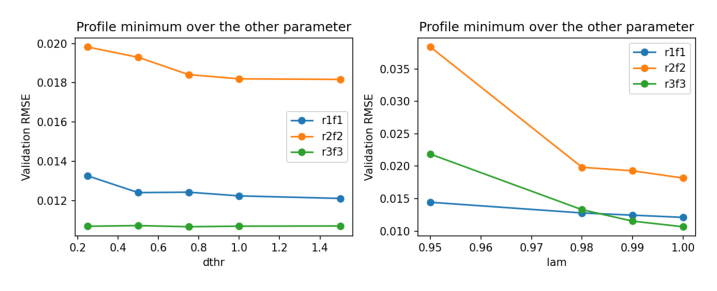

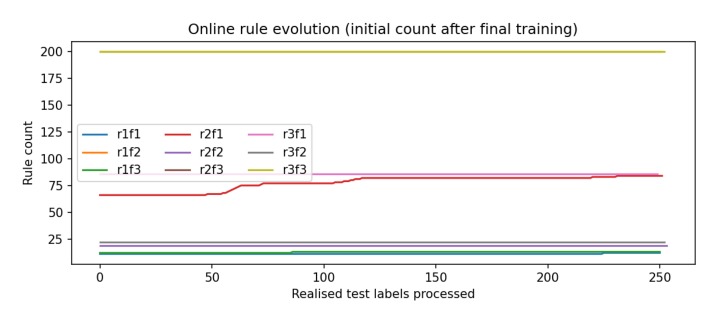

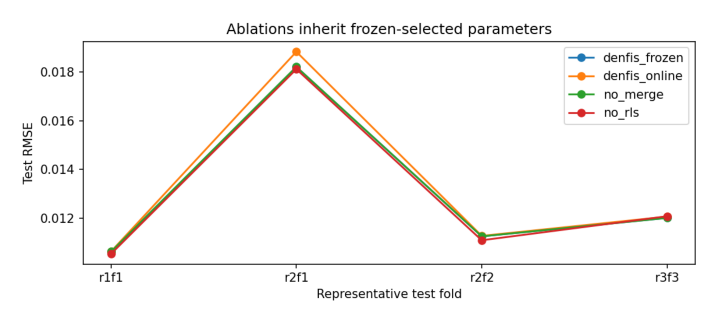

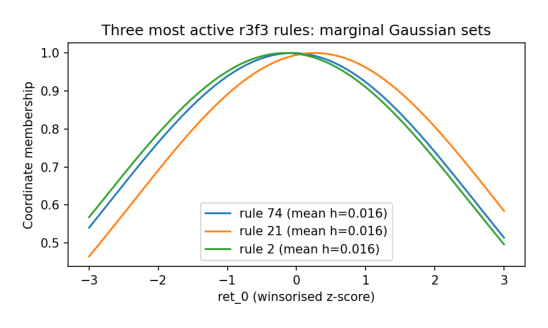

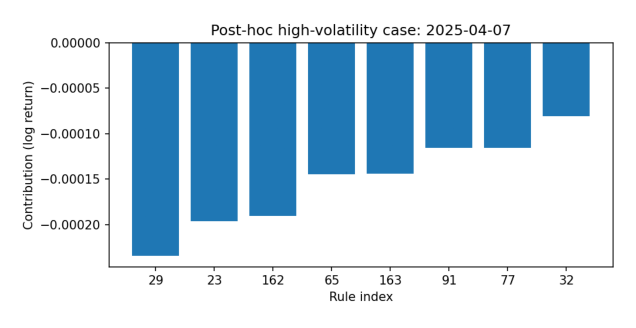

In [5]:
for name in ['denfis_sensitivity.png', 'denfis_rule_evolution.png', 'denfis_ablations.png', 'denfis_memberships.png', 'denfis_case_contributions.png']:
    path = root/'results/figures'/name
    assert path.exists(), path
    fig, ax = plt.subplots(figsize=(9,4))
    ax.imshow(plt.imread(path)); ax.axis('off'); plt.show()

## Transfer extension

Three aligned folds; separate market scalers. Do not pool these rows into nine-fold main results.

In [6]:
transfer = pd.read_csv('results/transfer/summary.csv')
print(transfer[['protocol','fold_id','rmse','da','sharpe']].to_string(index=False))

 protocol fold_id     rmse       da    sharpe
fine_tune    r1f1 0.010634 0.484000  0.729819
fine_tune    r2f2 0.011250 0.470356  0.047356
fine_tune    r3f3 0.012006 0.496032  1.984480
  scratch    r1f1 0.010644 0.504000  1.639465
  scratch    r2f2 0.011265 0.450593 -0.856021
  scratch    r3f3 0.012025 0.535714  1.248449
zero_shot    r1f1 0.010640 0.480000  1.170440
zero_shot    r2f2 0.011198 0.438735 -0.128845
zero_shot    r3f3 0.012076 0.476190  1.231534


# Reference register

Verified against author/institutional repositories or publisher records on
2026-11-10. These are related methods, not additional empirical baselines.

| Year | Reference and primary source | Role in this project |
|---|---|---|
| 1993 | J.-S. R. Jang, *ANFIS: Adaptive-Network-Based Fuzzy Inference System*, IEEE TSMC 23(3), 665–685. [Author publications](https://www.cs.nthu.edu.tw/~jang/publication.htm), DOI 10.1109/21.256541 | Adaptive-network fuzzy modelling; contrast fixed structure with evolving rules. |
| 1994 | D. N. Politis and J. P. Romano, *The Stationary Bootstrap*, JASA 89(428), 1303–1313. [Publisher](https://doi.org/10.1080/01621459.1994.10476870) | Dependent-return uncertainty estimation. |
| 1995 | F. X. Diebold and R. S. Mariano, *Comparing Predictive Accuracy*, JBES 13(3), 253–263. [Publisher](https://doi.org/10.1080/07350015.1995.10524599) | Paired forecast-loss comparison. |
| 1997 | S. Hochreiter and J. Schmidhuber, *Long Short-Term Memory*, Neural Computation 9(8), 1735–1780. [Author-hosted paper](https://www.bioinf.jku.at/publications/older/2604.pdf) | Recurrent temporal baseline; not evidence of financial profitability. |
| 2001 | Q. Song and N. Kasabov, *ECM—A Novel On-line, Evolving Clustering Method and Its Applications*. [AUT manuscript](https://kedri.aut.ac.nz/__data/assets/pdf_file/0018/23256/qs2001_36.pdf) | Normalised distance and centre/radius updates. |
| 2002 | N. Kasabov and Q. Song, *DENFIS: Dynamic Evolving Neural-Fuzzy Inference System and Its Application for Time-Series Prediction*, IEEE TFS 10(2), 144–154. [Institutional record](https://pure.ulster.ac.uk/en/publications/denfis-dynamic-evolving-neural-fuzzy-inference-system-and-its-app/), DOI 10.1109/91.995117 | Central established method; our Gaussian/two-pass/bounded variant is explicitly disclosed. |
| 2004 | P. Angelov and D. Filev, *An Approach to Online Identification of Takagi–Sugeno Fuzzy Models*, IEEE TSMC-B 34(1), 484–498. [Lancaster paper](https://eprints.lancs.ac.uk/id/eprint/899/1/SMC-B_paper.pdf) | Related evolving TS identification; not implemented here. |
| 2006 | H.-J. Rong, N. Sundararajan, G.-B. Huang and P. Saratchandran, *Sequential Adaptive Fuzzy Inference System (SAFIS) for Nonlinear System Identification and Prediction*, FSS 157, 1260–1275. [Publisher](https://doi.org/10.1016/j.fss.2005.12.011) | Rule influence and structural adaptation. Workplan's 2008 date is corrected to 2006. |
| 2014 | M. Pratama, S. G. Anavatti, P. Angelov and E. Lughofer, *PANFIS: A Novel Incremental Learning Machine*, IEEE TNNLS 25(1), 55–68. [Lancaster record](https://www.research.lancs.ac.uk/portal/en/publications/panfis(5750842e-9605-4058-90d6-079338408a32)/export.html), DOI 10.1109/TNNLS.2013.2271933 | Related incremental fuzzy architecture; no direct benchmark claim. |
| 2016 | T. Chen and C. Guestrin, *XGBoost: A Scalable Tree Boosting System*, KDD, 785–794. [Authors' preprint](https://arxiv.org/abs/1603.02754) | Regularised tree baseline. |
| 2023 | M. Yeganejou, K. Honari, R. Kluzinski, S. Dick, M. Lipsett and J. Miller, *DCNFIS: Deep Convolutional Neuro-Fuzzy Inference System*. [Authors' preprint](https://arxiv.org/abs/2308.06378) | Deep visual fuzzy modelling as a future direction, not a stock-return benchmark. |
| 2024 | M. Alateeq and W. Pedrycz, *Logic-oriented fuzzy neural networks: A survey*, Expert Systems with Applications 257, 125120, DOI 10.1016/j.eswa.2024.125120. [Publisher](https://www.sciencedirect.com/science/article/pii/S0957417424019870) | Modern review context, distinct from our empirical stock-return task. |

Do not claim state-of-the-art stock prediction from these citations. Only XGBoost
and LSTM are empirically compared under this repository's folds. Final reference numbering belongs to notebook integration.
